In [1]:
import gc
import geopandas as gpd
import json
import numpy as np
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import os
import pandas as pd
import scanpy as sc
from shapely.geometry import box
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score, v_measure_score

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [13]:
### HELPER FUNCTIONS

# @param:
#   - scale_path: path to scalefactors_json.json
# @return: 
#   - spot_px --> side length in pixels of one bin. 
#                 Depends on bin size, always in relation to the original image (Visium HD: .btf file) 
def get_binsize(scale_path):
    """
    Loads 'spot_diameter_fullres' from scalefactors_json.json.
    For Visium HD, this corresponds to the side length of a 2 µm bin in full-resolution pixels.
    """
    with open(scale_path, "r") as f:
        scales = json.load(f)

    # In full-resolution BTF coordinates, this is the correct field.
    spot_px = scales["spot_diameter_fullres"]
    return spot_px



# Assigns bins to image patches based on coordinates. Assumes crs=None (i.e. pixels).
# @param:
#   - bin_df: dataframe containg bin information, such as coordinates and clustering 
#   - patch_df: dataframe containg patch information, such as coordinates and clustering 
#   - bin_cols: list of column names to keep for merging from bins.
#   - patch_cols: list of column names to keep for mergin from patches. 
#   - id: string id column from bins (usually "barcode").
#   - scalefactor_path: string path to scalefactors_json.json. JSON should contain bin side length in pixels.
#   - output_dir: string directory to store resulting dataframe.
#   - box_size: integer patch size in pixels. For UNI model usually 224x224. 
#               NOTE, that both bins and patches are expected to be perfectly square.
# @return: 
#   - best_matches: dataframe. 1 bin = 1 row, with columns: 
#                   [bin_cols(...), patch_cols(...), patch_id, intersection_area, cell_area, percent_covered]
def assign_bins_to_patches(bin_df, patch_df, bin_cols, patch_cols, id, scalefactor_path, output_dir, box_size=224):
    if bin_df.shape[0] == 0 or patch_df.shape[0] == 0:
        print("WARNING: Empty bin or patch info does not contain any content. ")
        return {}
    # if (ground_truth[['pxl_col_in_fullres', 'pxl_row_in_fullres']].isna()):
        # print("WARNING: Empty entries in ground truth. Exiting. ")
        # return {}

    
    # 1. Turn patches into box polygons
    patch_geometries = [
        box(row['X'], row['Y'], row['X'] + box_size, row['Y'] + box_size)
        for _, row in patch_df.iterrows()
    ]
    #patches_gdf = gpd.GeoDataFrame(patch_df[['Patch_ID', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0']], geometry=patch_geometries, crs=None)
    patches_gdf = gpd.GeoDataFrame(patch_df[patch_cols], geometry=patch_geometries, crs=None)

    # 2. Turn bins into smaller box polygons
    scalefactor = get_binsize(scalefactor_path)
    print("scalefactor: ", scalefactor, type(scalefactor))
    bin_geometries = [
        box(row['pxl_col_in_fullres'], 
            row['pxl_row_in_fullres'], 
            row['pxl_col_in_fullres'] + scalefactor, 
            row['pxl_row_in_fullres'] + scalefactor)
        for _, row in bin_df.iterrows()
    ]
    #bins_gdf = gpd.GeoDataFrame(bin_df[['barcode', 'tissuetype', 'in_tissue']], geometry=bin_geometries, crs=None)
    bins_gdf = gpd.GeoDataFrame(bin_df[bin_cols], geometry=bin_geometries, crs=None)

    print(f"Patch bounds:", bins_gdf.total_bounds)  # minx, miny, maxx, maxy of nuclei
    print(f"Bin bounds:", patches_gdf.total_bounds)

    # 3. Spatial join: assign each bin to a patch it falls within ---
    overlaps = gpd.overlay(bins_gdf, patches_gdf, how='intersection')

    # 4. Compute overlap and total bin area
    overlaps['intersection_area'] = overlaps.geometry.area
    overlaps['cell_area'] = overlaps.groupby(id)['intersection_area'].transform('sum')

    overlaps['percent_covered'] = overlaps['intersection_area'] / overlaps['cell_area']

    # 5. Keep only the patch covering the largest fraction
    best_matches = (
        overlaps.sort_values('percent_covered', ascending=False)
        .drop_duplicates(subset='barcode')
        .copy()
    )

    del overlaps, bins_gdf, patches_gdf, patch_geometries
    gc.collect()

    best_matches = best_matches.drop(["geometry"], axis=1)
    best_matches = best_matches.set_index(id)
    best_matches.to_parquet(os.path.join(output_dir, "bin_patch_clusters.parquet"))
    return best_matches



# Plots total UMI distribution before and after setting UMI threshold cutoff
# @param: 
#   - adata_: AnnData File where we get UMI counts from
#   - cut_off: cut off value. User determined.  
def total_umi(adata_, cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # Box plot
    axs[0].boxplot(adata_.obs["total_counts"], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[0].set_title('Total Counts')

    # Box plot after filtering
    axs[1].boxplot(adata_.obs["total_counts"][adata_.obs["total_counts"] > cut_off], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[1].set_title('Total Counts > ' + str(cut_off))

    # Remove y-axis ticks and labels
    for ax in axs:
        ax.get_yaxis().set_visible(False)

    plt.tight_layout()
    plt.show()


# Plots all bins based on their original pixel position, colored based on clustering results.
# @param:
#   - df: dataframe containing all bin information 
#   - x_col: column name for x coordinates in pixels
#   - y_col: column name for y coordinates in pixels
#   - cluster_col: column name for clustering column
def plot_bin_clusters(df, x_col, y_col, cluster_col):
    # Extract needed data
    x = df[x_col]
    y = df[y_col]
    clusters = df[cluster_col]

    # Create DataFrame (optional, just for convenience)
    df = pd.DataFrame({
        'x': x,
        'y': y,
        'cluster': clusters
    })

    # Plot
    plt.figure(figsize=(8, 8))
    scatter = plt.scatter(
        df['x'],
        df['y'],
        c=df['cluster'].astype('category').cat.codes,  # assign colors by cluster
        cmap='tab20',  # or 'tab10', 'viridis', etc.
        s=0.01,           # point size
        alpha=0.8
    )

    # Reverse y-axis (since image coordinates often start from top-left)
    plt.gca().invert_yaxis()

    # Add colorbar and labels
    plt.colorbar(scatter, ticks=range(len(df['cluster'].unique())))
    plt.title(f'Spatial distribution by cluster with bin size')
    plt.xlabel('pxl_col_in_fullres')
    plt.ylabel('pxl_row_in_fullres')
    plt.show()


# Prints evaluation metrics: ARI, Normalised Mutual Info, Homogeneity, Completeness, V-Measure
# @param:
#   - df: dataframe containing bins with barcodes, true cluster column and predicted cluster column
#   - pred_col: predicted cluster column name
#   - truth_col: true cluster column name
def get_eval_scores(df, pred_col, truth_col):
    num_cluster_nans = df[pred_col].isna().sum()
    num_tissue_nans = df[truth_col].isna().sum()

    if num_cluster_nans > 0 or num_tissue_nans > 0:
        print(f"Found {num_cluster_nans} NaN values in '{pred_col}' and {num_tissue_nans} in '{truth_col}' out of {df.shape[0]} rows. Dropping rows ...")
        df = df.dropna(subset=[pred_col, truth_col])

    y_true = df['tissuetype']
    y_pred = df[pred_col]

    results = {
        'Adjusted Rand Index': adjusted_rand_score(y_true, y_pred),
        'Normalized Mutual Info': normalized_mutual_info_score(y_true, y_pred),
        'Homogeneity': homogeneity_score(y_true, y_pred),
        'Completeness': completeness_score(y_true, y_pred),
        'V-Measure': v_measure_score(y_true, y_pred)
    }

    for k, v in results.items():
        print(f"{k}: {v:.3f}")

# Histology

### UNI Model

In [ ]:
person = "CRC_P2"
bin_size = "002um"
pred_col = "leiden_0.2" # cluster resolution
patch_size = 224


base_dir = f"../../data/{person}/"
dir_base_output = os.path.join(base_dir, f"output/binned_outputs/square_{bin_size}")
histology_dir = f"../../uni/notebooks/metadata"

adata_patches = sc.read_h5ad(os.path.join(histology_dir, "filtered_WSI_patch_embeddings.h5ad"))
adata_patches = adata_patches[adata_patches.obs["Slide_ID"] == person]

# Extract needed info
df = adata_patches.obs[["Slide_ID", "X", "Y", pred_col]].copy()

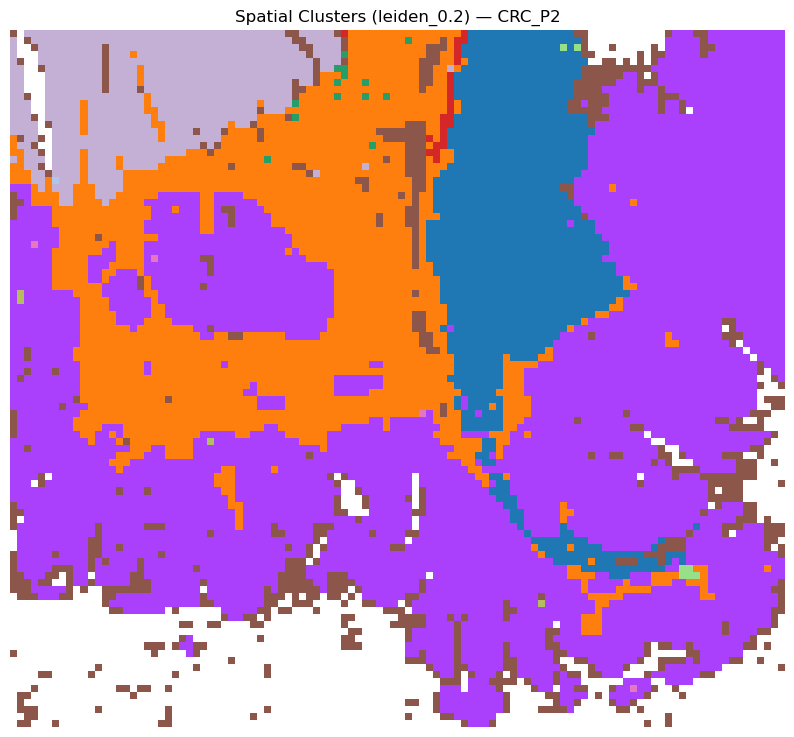

In [ ]:
if f"{pred_col}_colors" in adata_patches.uns:
    pred_df = sorted(df[pred_col].unique(), key=lambda x: int(x))
    colors = adata_patches.uns[f"{pred_col}_colors"]
    color_map = {c: colors[i % len(colors)] for i, c in enumerate(pred_df)}
else:
    unique_clusters = df[pred_col].unique()
    cmap = cm.get_cmap("tab20", len(unique_clusters))
    color_map = {c: cmap(i) for i, c in enumerate(unique_clusters)}

# Create figure
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title(f"Spatial Clusters ({pred_col}) — {person}")

# Draw each patch as a colored rectangle
for _, row in df.iterrows():
    x, y = row["X"], row["Y"]
    color = color_map[row[pred_col]]
    rect = patches.Rectangle(
        (x, y), patch_size, patch_size,
        facecolor=color, edgecolor='none'
    )
    ax.add_patch(rect)

# Set coordinate system: top-left = (0,0)
ax.set_xlim(df["X"].min(), df["X"].max() + patch_size)
ax.set_ylim(df["Y"].min() + patch_size, df["Y"].max())
ax.axis("off")

plt.show()

**Comparing with ground truth**  
Since this case deals with patches, but the ground truth is based on bins, we will first assign each bin to a patch.

Then we will evaluate.

In [ ]:
truth_df = pd.read_csv(os.path.join(base_dir, "ground_truth/2um_squares_annotation.csv"), 
                                        delimiter='\t', header=None, names=['barcode', 'tissuetype'])
tissue_positions = pd.read_parquet(os.path.join(dir_base_output, "spatial/tissue_positions.parquet"))
truth_df = pd.merge(truth_df, tissue_positions, on='barcode', how='left')

scale_path = os.path.join(dir_base_output, "spatial/scalefactors_json.json")

match_dir = os.path.join(base_dir, "ground_truth")
bin_cols = ['Patch_ID', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0']
patch_cols = ['barcode', 'tissuetype', 'in_tissue']
matched_df = assign_bins_to_patches(truth_df, adata_patches.obs, bin_cols, patch_cols, 'barcode', 
                                    scale_path, match_dir, 224)

In [ ]:
matched_df = pd.read_parquet(os.path.join(base_dir, "ground_truth/bin_patch_clusters.parquet"))

y_true = matched_df['tissuetype']
y_pred = matched_df['leiden_0.2']

results = {
    'Adjusted Rand Index': adjusted_rand_score(y_true, y_pred),
    'Normalized Mutual Info': normalized_mutual_info_score(y_true, y_pred),
    'Homogeneity': homogeneity_score(y_true, y_pred),
    'Completeness': completeness_score(y_true, y_pred),
    'V-Measure': v_measure_score(y_true, y_pred)
}

for k, v in results.items():
    print(f"{k}: {v:.3f}")


Adjusted Rand Index: 0.772
Normalized Mutual Info: 0.687
Homogeneity: 0.728
Completeness: 0.650
V-Measure: 0.687


# Transcriptomics

In [4]:
person = "CRC_P2"
bin_size = "008um"
base_dir = f"../../data/{person}"
dir_base_input = os.path.join(base_dir, "input")
dir_base_output = os.path.join(base_dir, f"output/binned_outputs/square_{bin_size}")

### For bin size 002um: 
We load the filtered feature matrix and assign each bin to a larger 8x8um bin. 
This information is stored in the same dataframe. 
 
We then ...

In [ ]:
adata_patches = sc.read_10x_h5(os.path.join(dir_base_output, "filtered_feature_bc_matrix.h5"))

# Load Spatial Coordinates
tissue_position_file = dir_base_output+'/spatial/tissue_positions.parquet'
df_tissue_positions=pd.read_parquet(tissue_position_file)

#Set the index of the dataframe to the barcodes
df_tissue_positions = df_tissue_positions.set_index('barcode')

# Create an index in the dataframe to check joins
df_tissue_positions['index']=df_tissue_positions.index

# Adding the tissue positions to the meta data
adata_patches.obs = pd.merge(adata_patches.obs, df_tissue_positions, left_index=True, right_index=True)

**Preprocessing.**  
We now plot the UMI distribution.
The goal is to select a cut off and filter out low-qaulity bins.

In [ ]:
# Calculate quality control metrics for the original AnnData object
sc.pp.calculate_qc_metrics(adata_patches, inplace=True)

Note on the bin size:  
"Each bin contains the gene-wise summation of the UMI counts of a number of 2x2 µm squares. For example, 8x8 µm binned data is the gene-wise sum of the UMI counts from a box that is 4 squares wide by 4 squares tall" (from https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd)

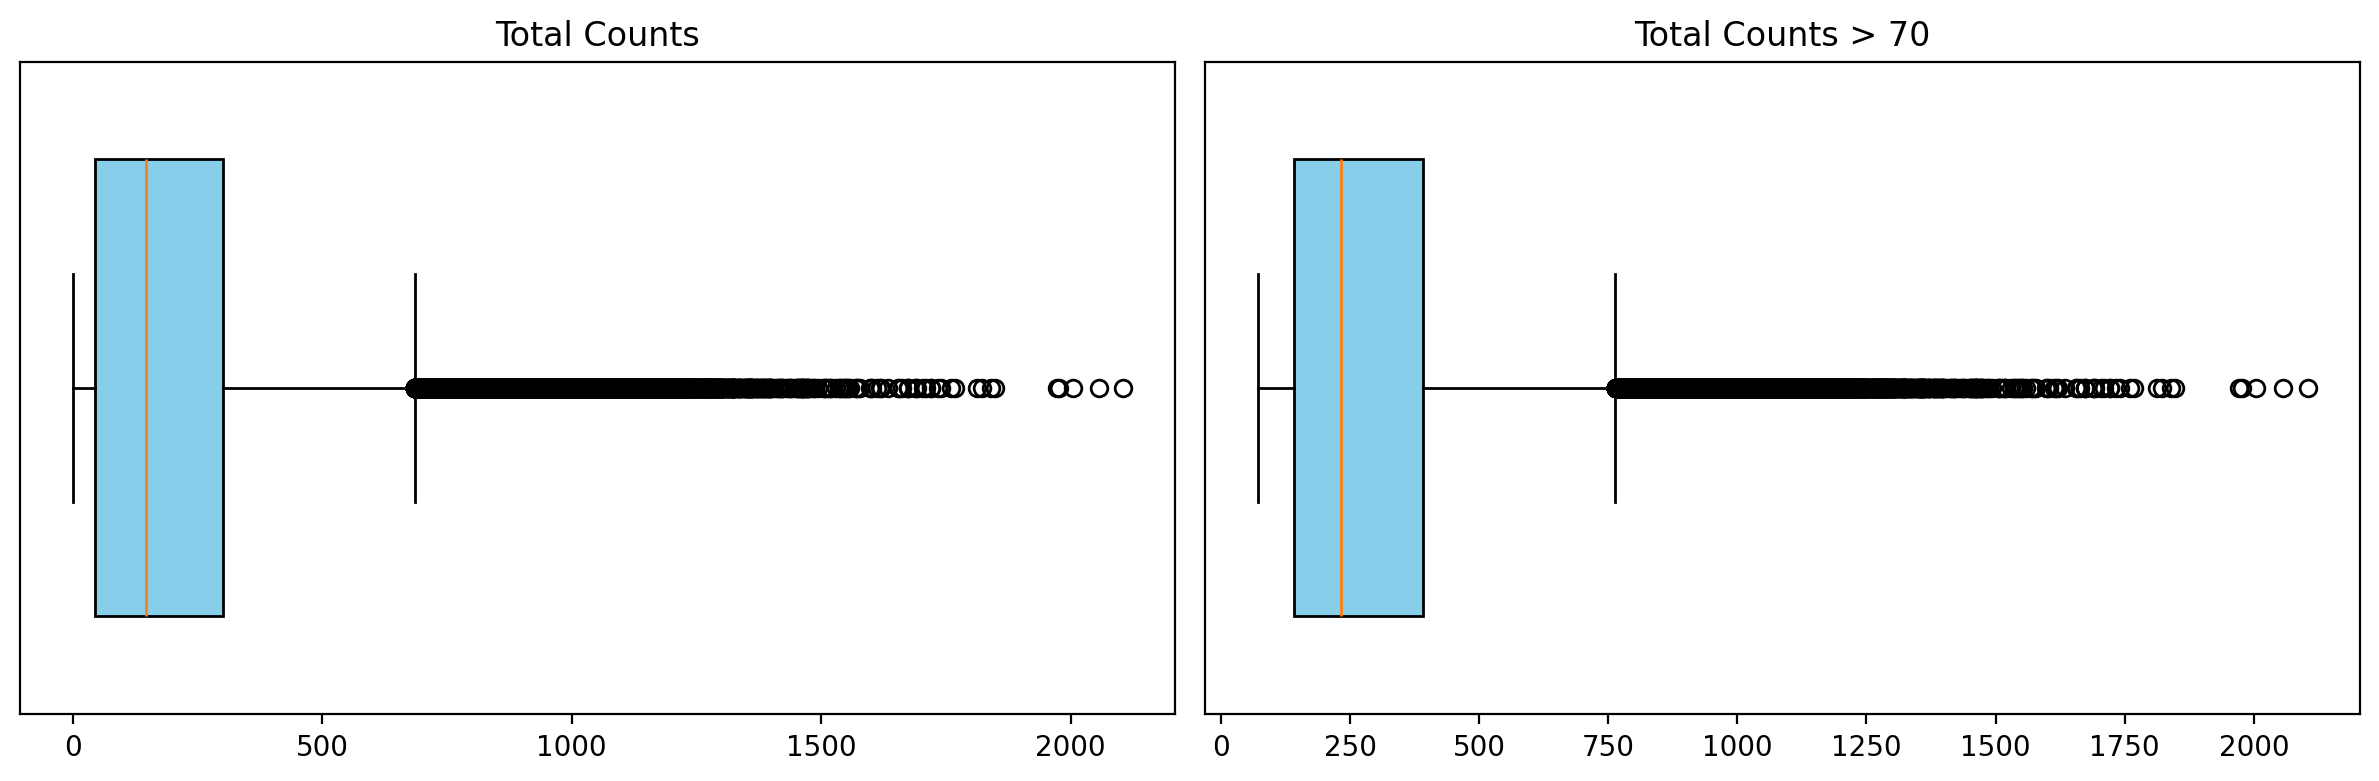

In [ ]:
# Plot total UMI distribution (here cutoff = 30. Adapt if necessary)
cutoff=70
total_umi(adata_patches, cutoff)

In [ ]:
# Create a mask based on the 'total_counts' column for values greater than 100
mask_count = adata_patches.obs['total_counts'] > cutoff
filtered_adata = adata_patches[mask_count, :]

# Calculate quality control metrics for the filtered AnnData object
sc.pp.calculate_qc_metrics(filtered_adata, inplace=True)

del mask_count, adata_patches

_qc.py (140): Trying to modify attribute `.obs` of view, initializing view as actual.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [7]:
# Normalize total counts for each cell in the AnnData object
sc.pp.normalize_total(filtered_adata, inplace=True)

# Logarithmize the values in the AnnData object after normalization
sc.pp.log1p(filtered_adata)

# Identify highly variable genes in the dataset using the Seurat method
sc.pp.highly_variable_genes(filtered_adata, flavor="seurat", n_top_genes=2000)

# Perform Principal Component Analysis (PCA) on the AnnData object
sc.pp.pca(filtered_adata)

# Build a neighborhood graph based on PCA components
sc.pp.neighbors(filtered_adata)

# Perform Leiden clustering on the neighborhood graph and store the results in 'clusters' column

# Adjust the resolution parameter as needed for different samples
sc.tl.leiden(filtered_adata, resolution=0.2, key_added="clusters")

auto.py (21): IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
4280293919.py (19): In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


KeyboardInterrupt: 

In [ ]:
plot_bin_clusters(filtered_adata.obs, 'pxl_col_in_fullres', 'pxl_row_in_fullres', 'clusters')

### For bin size 008um and 016um
Clustering results are already provided by 10x Genomics. 
Hence, we just use the same plotting function, but for larger bins.

In [14]:
cluster_type = "kmeans_6_clusters" # in spaceranger output: either kmeans or graphclust. Also name of directory
pred_col = "Cluster" # column with predicted cluster info in csv 
pred_cluster_path = os.path.join(dir_base_output, f"analysis/clustering/gene_expression_{cluster_type}/clusters.csv")
pred_df = pd.read_csv(pred_cluster_path, delimiter=',')
pred_df.rename(columns={'Barcode': 'barcode'}, inplace=True)

# Merge cluster annotation with the bin positions
tissue_positions = pd.read_parquet(os.path.join(dir_base_output, "spatial/tissue_positions.parquet"))
pred_df = pd.merge(pred_df, tissue_positions, on='barcode', how='left')
del tissue_positions

truth_col = "tissuetype"
truth_df = pd.read_csv(os.path.join(base_dir, "ground_truth/8um_squares_annotation.csv"), 
                                        delimiter='\t', header=None, names=['barcode', 'tissuetype'])
tissue_positions = pd.read_parquet(os.path.join(base_dir, f"output/binned_outputs/square_{bin_size}/spatial/tissue_positions.parquet"))
truth_df = pd.merge(truth_df, tissue_positions, on='barcode', how='left')

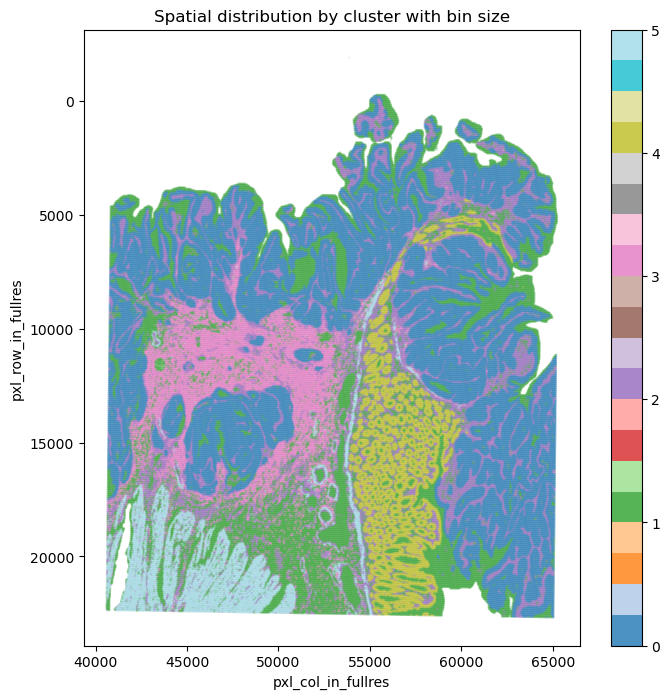

In [16]:
# Plotting the Clusters given in the spaceranger analysis 
plot_bin_clusters(pred_df, 'pxl_col_in_fullres', 'pxl_row_in_fullres', pred_col)

In [ ]:
merged_df = pd.merge(truth_df, pred_df, on='barcode', how='left')

get_eval_scores(merged_df, pred_col, truth_col)

Found 63 NaN values in 'Cluster' and 0 in 'tissuetype' out of 545913 rows. Dropping rows ...
Adjusted Rand Index: 0.182
Normalized Mutual Info: 0.361
Homogeneity: 0.548
Completeness: 0.269
V-Measure: 0.361


In [15]:
merged_df = pd.merge(truth_df, pred_df, on='barcode', how='left')
get_eval_scores(merged_df, pred_col, truth_col)

Found 63 NaN values in 'Cluster' and 0 in 'tissuetype' out of 545913 rows. Dropping rows ...
Adjusted Rand Index: 0.401
Normalized Mutual Info: 0.414
Homogeneity: 0.487
Completeness: 0.360
V-Measure: 0.414
